# The Law of Large Numbers and the Central Limit Theorem

![Gaussian Inksplats](gaussian-ink.png)

## Introduction

We often use an average to estimate an unknown quantity, such as the probability that a coin lands on heads. But an average calculated from one set of observations will differ from an average calculated from another. To use these estimates well, we need to understand how much they vary and what collecting more data actually improves.  The Law of Large Numbers and the Central Limit Theorem give us a foundation for understanding this behavior.  In this post, we'll build that understanding through a sequence of coin-toss simulations. After each simulation, we'll introduce the terminology and theory needed to explain the result. The aim is to understand what each theorem tells us about an estimate and what guarantees it provides.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-darkgrid')
from scipy.stats import binom, norm

random_generator = np.random.default_rng(2026)
heads_probability = 0.6

In [2]:
plt.rcParams.update({
    'figure.figsize': (8, 4),
    'axes.grid': True,
    'grid.alpha': 0.18,
    'font.size': 11,
})

## Twenty Tosses

Let's simulate 20 independent tosses. We already know that each toss has a fixed chance of producing heads, regardless of the previous results.  The fraction of heads is simply the number of heads divided by the number of tosses. 

In [26]:
tosses = random_generator.binomial(1, heads_probability, size=20)
number_of_heads = tosses.sum()
fraction_of_heads = number_of_heads / len(tosses)

print('Tosses:', ' '.join('H' if outcome else 'T' for outcome in tosses))
print(f'Heads: {number_of_heads} out of {len(tosses)}')
print(f'Fraction of heads: {fraction_of_heads:.2f}')

Tosses: H H H H H T T T H T T H T T H H H T T H
Heads: 11 out of 20
Fraction of heads: 0.55


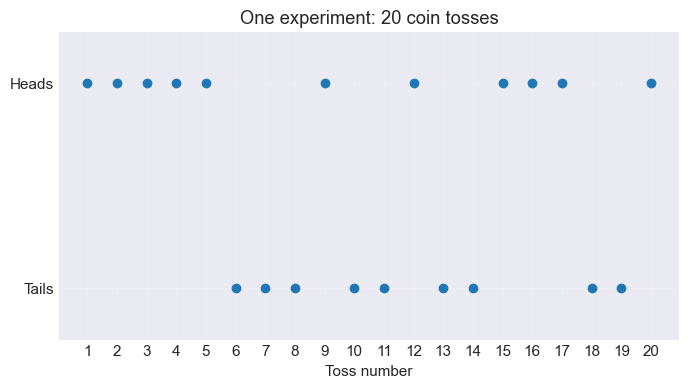

In [28]:
figure, axis = plt.subplots()
toss_numbers = np.arange(1, len(tosses) + 1)
axis.scatter(toss_numbers, tosses)
axis.set(xticks=toss_numbers, yticks=[0, 1], yticklabels=['Tails', 'Heads'],
         ylim=(-0.25, 1.25), xlabel='Toss number', title='One experiment: 20 coin tosses')
plt.show()

Each toss produced a head or a tail, but their average can lie between 0 and 1. We obtained 11 heads from 20 tosses, giving a fraction of 0.55. This fraction is an estimate of the coin's heads probability.

### Bernoulli Variables and the Sample Mean

A single toss recorded as 0 or 1 is a Bernoulli random variable. Writing $p$ for the probability of heads,

$$
P(X=1)=p,\qquad P(X=0)=1-p.
$$

Its expected value is the probability-weighted average of the two outcomes:

$$
\mu=E[X]=1\cdot p+0\cdot(1-p) 
$$

The average calculated from a finite set of observations is called the sample mean. For $n$ tosses,

$$
\bar X_n=\frac{1}{n}\sum_{i=1}^n X_i.
$$

Because heads is 1 and tails is 0, this is also the fraction of heads. In our first 20 tosses, $\bar X_{20}=0.55$. Let's see how this sample mean changes when we keep collecting observations.

## Keep Tossing

We'll extend this sequence to 10,000 tosses. After each new toss, we'll calculate the fraction of heads seen so far. The two panels show the beginning of the sequence and the full run.

In [33]:
additional_tosses = random_generator.binomial(1, heads_probability, size=10_000 - len(tosses))
tosses = np.concatenate([tosses, additional_tosses])
toss_numbers = np.arange(1, len(tosses) + 1)
cumulative_heads = np.cumsum(tosses)
running_fractions = cumulative_heads / toss_numbers

for number_of_tosses in [20, 100, 1000, 10_000]:
    current_fraction = running_fractions[number_of_tosses - 1]
    print(f'{number_of_tosses:>6,} tosses: fraction of heads = {current_fraction:.4f}')

    20 tosses: fraction of heads = 0.5500
   100 tosses: fraction of heads = 0.5600
 1,000 tosses: fraction of heads = 0.5950
10,000 tosses: fraction of heads = 0.6067


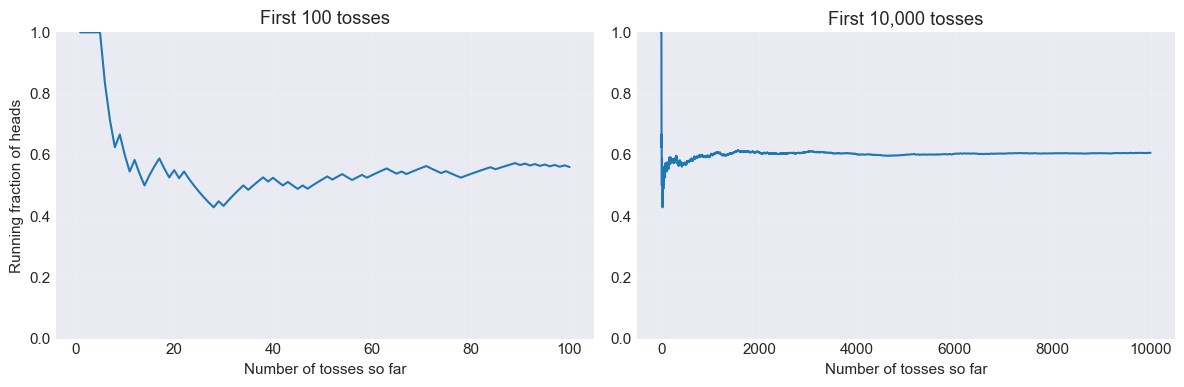

In [36]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, number_to_show in zip(axes, [100, 10_000]):
    axis.plot(toss_numbers[:number_to_show], running_fractions[:number_to_show])
    axis.set(xlabel='Number of tosses so far', ylim=(0, 1), title=f'First {number_to_show:,} tosses')
axes[0].set_ylabel('Running fraction of heads')
plt.tight_layout()
plt.show()

The running fraction fluctuates substantially at the beginning and becomes more stable later. In this run, the estimate was 0.6100 after 100 tosses, moved to 0.5740 after 1,000, and reached 0.5943 after 10,000. Collecting more data improved the overall stability, but did not make the error decrease at every checkpoint.

### The Law of Large Numbers

The stabilization we just saw illustrates the Law of Large Numbers. For independent observations drawn from the same distribution, with a finite absolute expectation and mean $\mu$, the strong law states that

$$
\bar X_n\longrightarrow\mu\qquad\text{with probability 1 as }n\to\infty.
$$

Here, independent means that one toss does not affect the others, and identically distributed means that each toss uses the same heads probability.  The theorem describes the behavior as the sequence grows indefinitely. Next, let's run this experiment many times and try to aggregate the results. 

## Start Again, Many Times

This time, one experiment will consist of 25 tosses followed by a single calculation: the fraction of heads. We'll repeat the whole experiment 10,000 times, starting afresh each time. The histogram will have one entry per experiment, showing the number of heads in that set of 25 tosses.

In [37]:
tosses_per_experiment = 25
number_of_experiments = 10_000
# Each row is a fresh experiment; each column is one toss.
experiments = random_generator.binomial(
    1, heads_probability, size=(number_of_experiments, tosses_per_experiment)
)
head_counts = experiments.sum(axis=1)
fractions_of_heads = head_counts / tosses_per_experiment
possible_counts = np.arange(tosses_per_experiment + 1)
count_frequencies = np.bincount(head_counts, minlength=tosses_per_experiment + 1)
observed_frequencies = count_frequencies / number_of_experiments

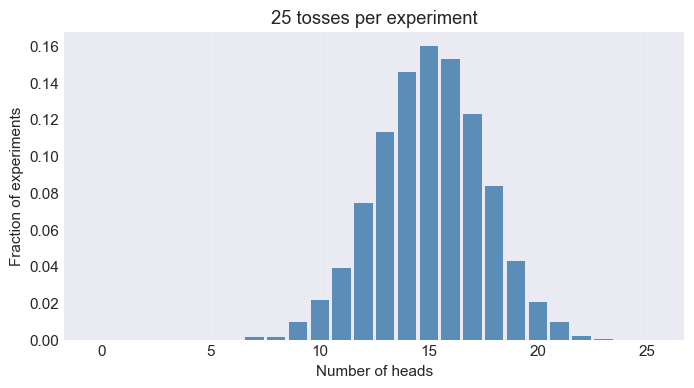

In [8]:
figure, axis = plt.subplots()
axis.bar(possible_counts, observed_frequencies, width=0.85, color='#5B8DB8')
axis.set(xlabel='Number of heads', ylabel='Fraction of experiments', title='25 tosses per experiment')
plt.show()

The head counts differ from run to run. They cluster around 15 heads out of 25 tosses, corresponding to a fraction of 0.6. Fewer experiments produce counts far from that value.

### Counts, Fractions, and Sampling Distributions

The count of heads in $n$ independent tosses has a binomial distribution:

$$
S_n=\sum_{i=1}^n X_i\sim\operatorname{Binomial}(n,p).
$$

The sample mean is the same count divided by $n$: $\bar X_n=S_n/n$. A count of 15 heads in 25 tosses gives a sample mean of 0.6. The distribution of sample means across fresh repetitions is called the sampling distribution of the mean. There are two sample sizes here: $n$, the number of tosses inside an experiment, and $K$, the number of times we repeat it. Each repetition produces one count and one sample mean. Let's first change $K$ while holding $n$ fixed.

## More Repetitions, Same Number of Tosses

We'll use only five tosses per experiment.  We'll compare 100, 10,000, and 1,000,000 repetitions while keeping those five tosses per experiment fixed. 

In [9]:
tosses_per_experiment = 5
repetition_counts = [100, 10_000, 1_000_000]
possible_counts = np.arange(tosses_per_experiment + 1)
possible_fractions = possible_counts / tosses_per_experiment
frequencies_by_repetition_count = {}

for number_of_experiments in repetition_counts:
    head_counts = random_generator.binomial(
        tosses_per_experiment, heads_probability, size=number_of_experiments
    )
    count_frequencies = np.bincount(head_counts, minlength=tosses_per_experiment + 1)
    observed_frequencies = count_frequencies / number_of_experiments
    frequencies_by_repetition_count[number_of_experiments] = observed_frequencies

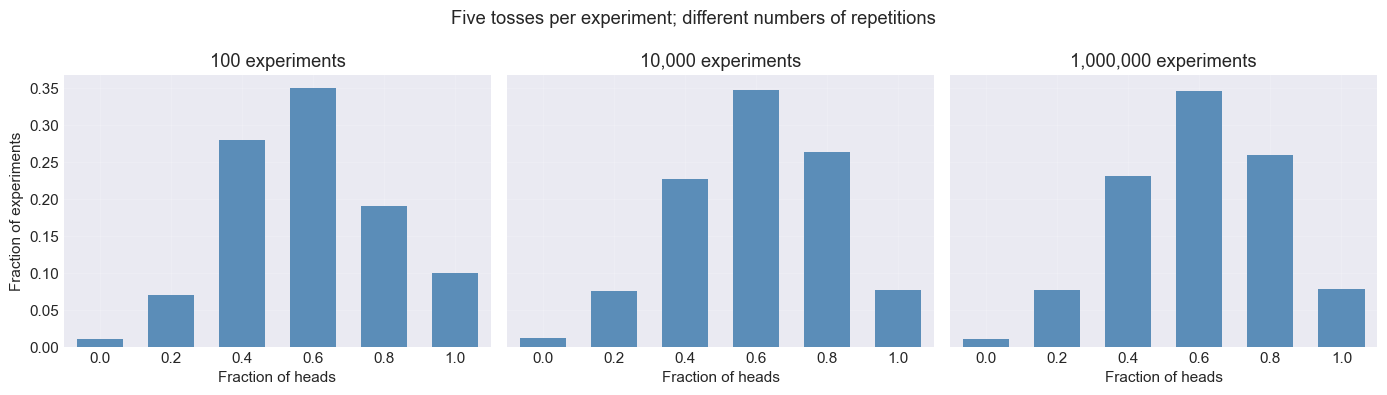

In [10]:
figure, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for axis, number_of_experiments in zip(axes, repetition_counts):
    observed_frequencies = frequencies_by_repetition_count[number_of_experiments]
    axis.bar(possible_fractions, observed_frequencies, width=0.13, color='#5B8DB8')
    axis.set(xlim=(-0.1, 1.1), xticks=possible_fractions, xlabel='Fraction of heads',
             title=f'{number_of_experiments:,} experiments')
axes[0].set_ylabel('Fraction of experiments')
figure.suptitle('Five tosses per experiment; different numbers of repetitions')
plt.tight_layout()
plt.show()

The last two plots are similar. More repetitions give us a clearer picture of how often each estimate occurs, but each estimate is still based on just five tosses. There are still only six possible fractions, with a substantial spread between experiments. Increasing the number of repetitions helps us see the sampling distribution more accurately. It does not make the estimate from any one five-toss experiment more reliable.

### Checking the Frequencies Against the Binomial Formula

The last plots suggest that the distribution settles into a fixed shape as we collect more repetitions. The binomial distribution gives the exact probabilities to compare against:

$$
P(S_n=k)=\binom nk p^k(1-p)^{n-k},\qquad k=0,\ldots,n.
$$

The factor $\binom nk$ counts the ways to place $k$ heads among $n$ tosses. Each such sequence has probability $p^k(1-p)^{n-k}$.

Dividing the count by $n$ gives the corresponding sample mean, so

$$
P\left(\bar X_n=\frac{k}{n}\right)=\binom nk p^k(1-p)^{n-k}.
$$

This formula depends on the toss count $n$ and heads probability $p$, but not the repetition count $K$. Let's overlay it on the frequencies from the million five-toss experiments we just ran.

In [38]:
tosses_per_experiment = 5
possible_counts = np.arange(tosses_per_experiment + 1)
possible_fractions = possible_counts / tosses_per_experiment
observed_frequencies = frequencies_by_repetition_count[1_000_000]
exact_probabilities = binom.pmf(possible_counts, tosses_per_experiment, heads_probability)

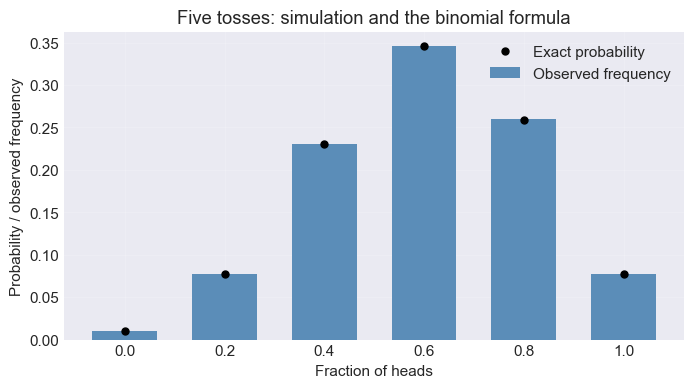

In [39]:
figure, axis = plt.subplots()
axis.bar(possible_fractions, observed_frequencies, width=0.13, color='#5B8DB8', label='Observed frequency')
axis.plot(possible_fractions, exact_probabilities, 'ko', markersize=5, label='Exact probability')
axis.set(xticks=possible_fractions, xlabel='Fraction of heads', ylabel='Probability / observed frequency',
         title='Five tosses: simulation and the binomial formula')
axis.legend()
plt.show()

The observed frequencies closely match the exact probabilities. 

## More Tosses in Each Experiment

Now we'll keep 50,000 repetitions and change the number of tosses inside each experiment: 5, 25, 100, and 1,000. We'll also print the fraction of estimates more than 0.1 away from 0.6, giving us a concrete way to compare their accuracy.

In [13]:
experiment_sizes = [5, 25, 100, 1000]
number_of_experiments = 50_000
fractions_by_size = {}
frequencies_by_size = {}
large_error_rates = {}

print('Tosses per experiment    Fraction with error greater than 0.1')
for tosses_per_experiment in experiment_sizes:
    head_counts = random_generator.binomial(
        tosses_per_experiment, heads_probability, size=number_of_experiments
    )
    fractions = head_counts / tosses_per_experiment
    fractions_by_size[tosses_per_experiment] = fractions
    count_frequencies = np.bincount(head_counts, minlength=tosses_per_experiment + 1)
    frequencies_by_size[tosses_per_experiment] = count_frequencies / number_of_experiments

    # Compare counts so floating-point rounding cannot move a boundary case.
    count_errors = np.abs(head_counts - tosses_per_experiment * heads_probability)
    error_threshold = tosses_per_experiment * 0.1
    large_error_rate = np.mean(count_errors > error_threshold + 1e-12)
    large_error_rates[tosses_per_experiment] = large_error_rate
    print(f'{tosses_per_experiment:>10,}                         {large_error_rate:.4f}')

Tosses per experiment    Fraction with error greater than 0.1
         5                         0.6554
        25                         0.3050
       100                         0.0320
     1,000                         0.0000


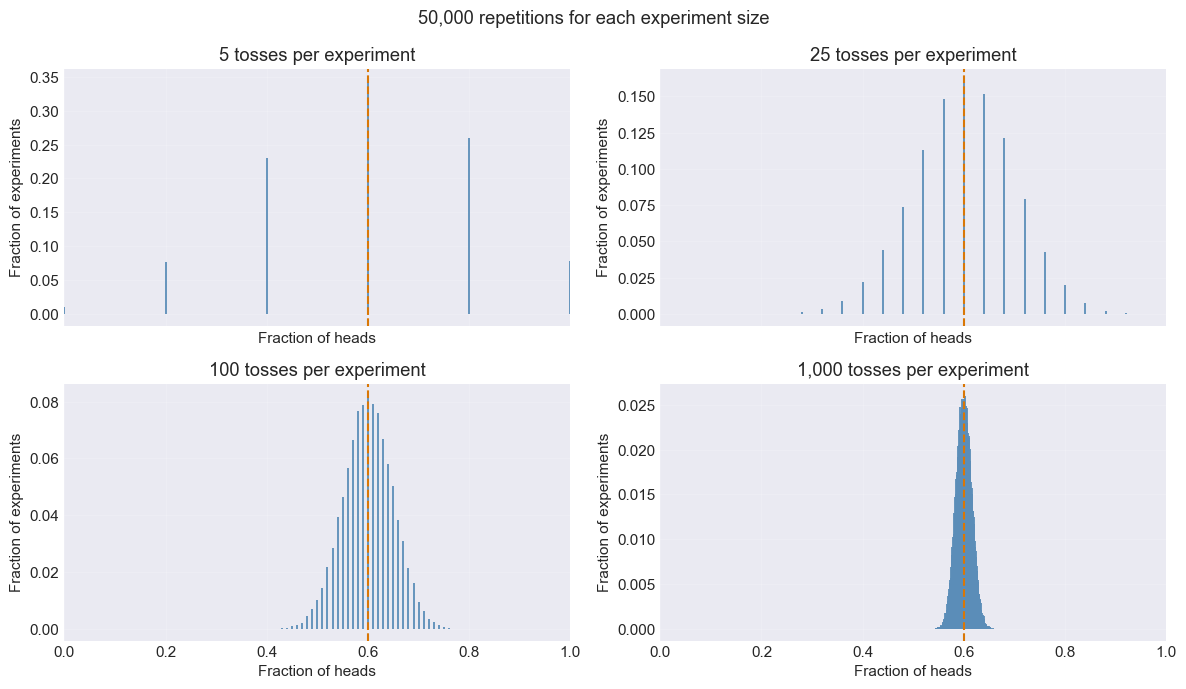

In [14]:
figure, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for axis, tosses_per_experiment in zip(axes.flat, experiment_sizes):
    possible_fractions = np.arange(tosses_per_experiment + 1) / tosses_per_experiment
    observed_frequencies = frequencies_by_size[tosses_per_experiment]
    axis.vlines(possible_fractions, 0, observed_frequencies, color='#5B8DB8', linewidth=1.3)
    axis.axvline(heads_probability, linestyle='--', color='#D97706')
    axis.set(xlim=(0, 1), title=f'{tosses_per_experiment:,} tosses per experiment',
             xlabel='Fraction of heads', ylabel='Fraction of experiments')
figure.suptitle('50,000 repetitions for each experiment size')
plt.tight_layout()
plt.show()

With more tosses in each experiment, the estimates cluster more tightly around 0.6. Large errors become less frequent. There are also more possible fractions: five tosses allow six values, while 1,000 tosses allow 1,001 values. The distribution becomes narrower even though there are more values it could take. These plots show the Law of Large Numbers from another perspective: across independent experiments, a large error becomes less likely as the toss count increases.

### Concentration and Standard Error

The previous plots showed that estimates cluster more tightly around 0.6 as the number of tosses increases. The weak Law of Large Numbers expresses this as

$$
P(|\bar X_n-\mu|>\epsilon)\longrightarrow0
\qquad\text{as }n\to\infty.
$$

For any fixed tolerance $\epsilon>0$, the probability of exceeding that error approaches zero. Our table illustrated this with $\epsilon=0.1$.

We can quantify the narrowing using variance. Each Bernoulli toss has variance $\sigma^2=p(1-p)=0.24$. For $n$ independent tosses, the variance of the sum is $n\sigma^2$. Dividing by $n$ to obtain the average divides the variance by $n^2$:

$$
\operatorname{Var}(\bar X_n)
=\frac{n\sigma^2}{n^2}
=\frac{\sigma^2}{n}.
$$

The standard deviation of the sample mean is called its standard error:

$$
\operatorname{SE}(\bar X_n)
=\frac{\sigma}{\sqrt n}
=\sqrt{\frac{0.24}{n}}.
$$

It measures how much estimates vary across independent experiments of the same size. Four times as many tosses halve this spread. Let's compare the predicted standard errors with those observed in our simulations.

In [15]:
sample_sizes = np.array([5, 10, 25, 50, 100, 200, 500, 1000, 5000, 10000])
individual_variance = heads_probability * (1 - heads_probability)
standard_errors = np.sqrt(individual_variance / sample_sizes)

print('Tosses    Theoretical standard error    Observed standard deviation')
for sample_size in experiment_sizes:
    standard_error = np.sqrt(individual_variance / sample_size)
    observed_spread = fractions_by_size[sample_size].std(ddof=1)
    print(f'{sample_size:>6,}               {standard_error:.5f}                       {observed_spread:.5f}')

Tosses    Theoretical standard error    Observed standard deviation
     5               0.21909                       0.21980
    25               0.09798                       0.09807
   100               0.04899                       0.04905
 1,000               0.01549                       0.01549


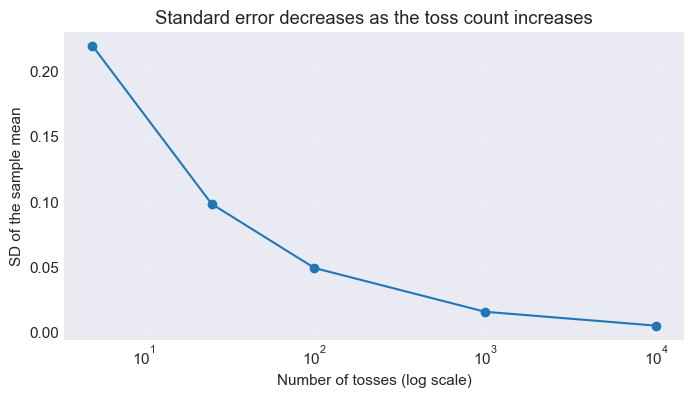

In [40]:
figure, axis = plt.subplots()
axis.plot(sample_sizes, standard_errors, marker='o')
axis.set_xscale('log')
axis.set(xlabel='Number of tosses (log scale)', ylabel='SD of the sample mean',
         title='Standard error decreases as the toss count increases')
plt.show()

The theoretical and observed spreads agree closely. For 100 tosses, the formula predicts about 0.04899, compared with 0.04905 in our simulation.  This explains the width of the sampling distribution. Next, we'll remove the difference in width to compare its shape.

## Zoom In on the Remaining Errors

The last plots make the narrowing clear, but make the shape harder to compare. Let's put the errors on a common scale.

For each set of estimates, we'll subtract the mean (0.6). Then we'll divide by the observed standard deviation of that set, our empirical estimate of its standard error. An error of one on the new axis means one standard deviation above 0.6; an error of minus one means one standard deviation below it. We'll use density histograms here: bar area represents the fraction of experiments, so the total area is one. This lets us compare shapes even when the spacing between possible values changes.

In [17]:
observed_spreads = {}
scaled_errors_by_size = {}
print('Tosses per experiment    Observed standard deviation of the fractions')
for tosses_per_experiment in experiment_sizes:
    fractions = fractions_by_size[tosses_per_experiment]
    observed_spread = fractions.std(ddof=1)
    errors = fractions - heads_probability
    scaled_errors = errors / observed_spread
    observed_spreads[tosses_per_experiment] = observed_spread
    scaled_errors_by_size[tosses_per_experiment] = scaled_errors
    print(f'{tosses_per_experiment:>10,}                         {observed_spread:.5f}')

Tosses per experiment    Observed standard deviation of the fractions
         5                         0.21980
        25                         0.09807
       100                         0.04905
     1,000                         0.01549


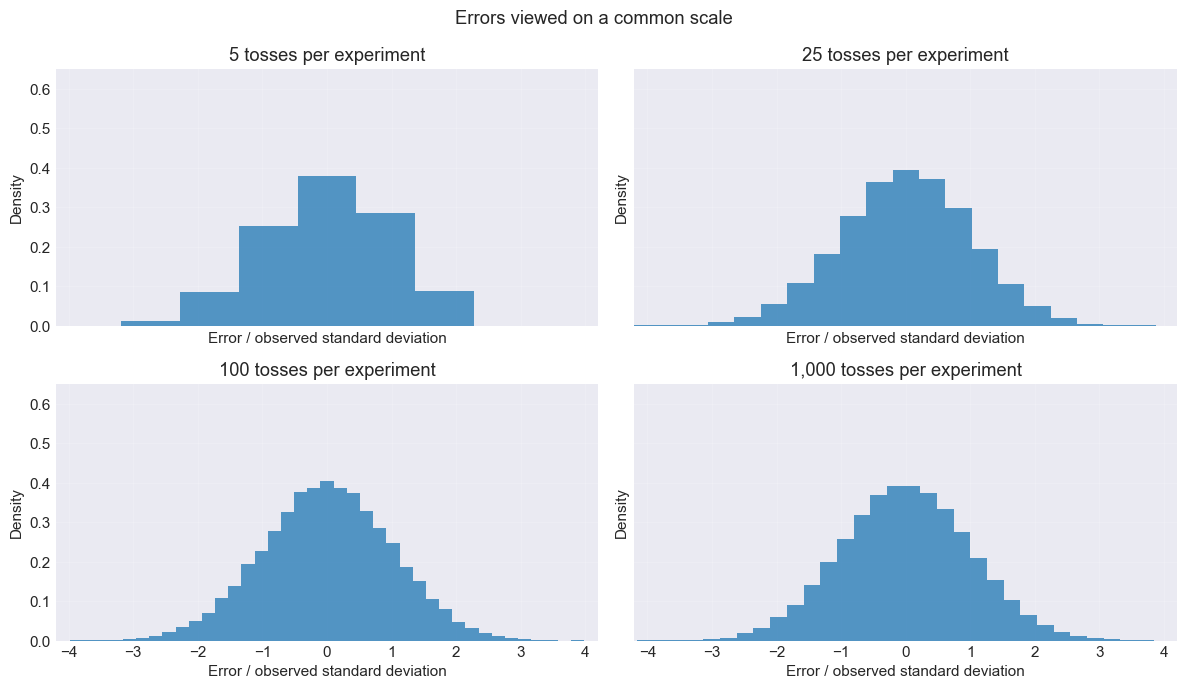

In [41]:
figure, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for axis, tosses_per_experiment in zip(axes.flat, experiment_sizes):
    observed_spread = observed_spreads[tosses_per_experiment]
    scaled_errors = scaled_errors_by_size[tosses_per_experiment]
    spacing = 1 / (tosses_per_experiment * observed_spread)
    # Keep separate bars for small samples; group nearby values for large samples.
    counts_per_bin = max(1, int(np.ceil(0.2 / spacing)))
    count_edges = np.arange(-0.5, tosses_per_experiment + counts_per_bin, counts_per_bin)
    fraction_edges = count_edges / tosses_per_experiment
    scaled_edges = (fraction_edges - heads_probability) / observed_spread
    axis.hist(scaled_errors, bins=scaled_edges, density=True, alpha=0.75)
    axis.set(xlim=(-4.2, 4.2), ylim=(0, 0.65), xlabel='Error / observed standard deviation',
             ylabel='Density', title=f'{tosses_per_experiment:,} tosses per experiment')
figure.suptitle('Errors viewed on a common scale')
plt.tight_layout()
plt.show()

After rescaling, the larger experiments have a similar bell-shaped pattern. 

## The Central Limit Theorem

Rescaling the errors suggested a bell-shaped pattern. The Law of Large Numbers tells us that the sample mean approaches the true mean. It doesn't tell us the *shape* of the remaining fluctuations. That's where the Central Limit Theorem (CLT) comes in.

For independent, identically distributed observations with finite mean $\mu$ and finite, nonzero variance $\sigma^2$, the CLT states that

$$
Z_n=\frac{\bar X_n-\mu}{\sigma/\sqrt n}\xrightarrow{d}\mathcal N(0,1)
$$

Notice that the theorem is about the centered and standardized sample mean, not the raw observations and not the unscaled sample mean.  For large but finite $n$, the same result motivates the practical approximation.
$$
\bar X_n\approx\mathcal N\left(\mu,\frac{\sigma^2}{n}\right).
$$

For our coin, that becomes $\mathcal N(0.6,0.24/n)$. Remember that it's an approximation: the true distribution of $\bar X_n$ is discrete for every finite $n$. Let's plot the exact standardized distributions for increasing $n$ against the standard Gaussian density. 

In [19]:
standardized_distributions = {}
for sample_size in experiment_sizes:
    possible_counts = np.arange(sample_size + 1)
    possible_fractions = possible_counts / sample_size
    standard_error = np.sqrt(individual_variance / sample_size)
    standardized_values = (possible_fractions - heads_probability) / standard_error
    probabilities = binom.pmf(possible_counts, sample_size, heads_probability)
    spacing = 1 / (sample_size * standard_error)
    standardized_distributions[sample_size] = (standardized_values, probabilities, spacing)

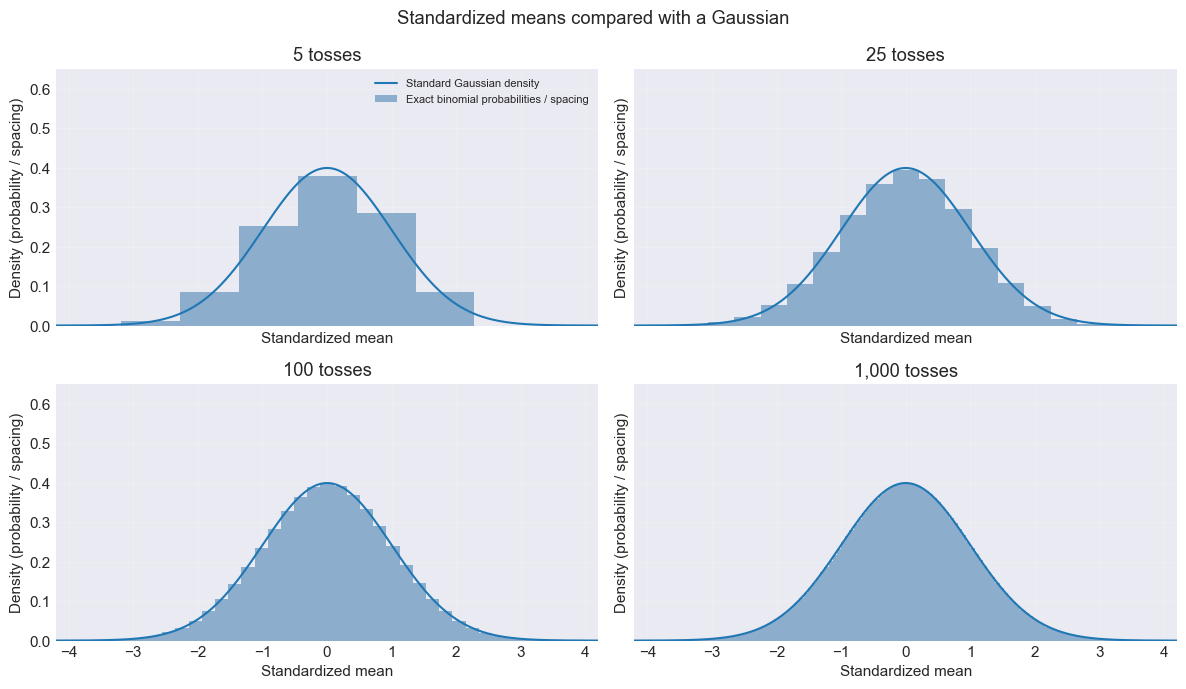

In [42]:
figure, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
gaussian_grid = np.linspace(-4.2, 4.2, 501)
for axis, sample_size in zip(axes.flat, experiment_sizes):
    standardized_values, probabilities, spacing = standardized_distributions[sample_size]
    density_heights = probabilities / spacing
    axis.bar(standardized_values, density_heights, width=spacing, alpha=0.65,
             color='#5B8DB8', label='Exact binomial probabilities / spacing')
    axis.plot(gaussian_grid, norm.pdf(gaussian_grid), label='Standard Gaussian density')
    axis.set(xlim=(-4.2, 4.2), ylim=(0, 0.65), xlabel='Standardized mean',
             ylabel='Density (probability / spacing)', title=f'{sample_size:,} tosses')
axes[0, 0].legend(fontsize=8)
figure.suptitle('Standardized means compared with a Gaussian')
plt.tight_layout()
plt.show()

## Confidence Intervals

The CLT gives us a way to quantify the uncertainty in a sample mean using a single observed dataset. We usually do not know the standard deviation $\sigma$, so we estimate it using the sample standard deviation, $s$:

$$
s^2=\frac{1}{n-1}\sum_{i=1}^n(X_i-\bar X_n)^2.
$$

For a sufficiently large independent sample, an approximate 95% confidence interval for the true mean is

$$
\bar X_n\pm1.96\frac{s}{\sqrt n}.
$$

The number 1.96 comes from the standard Gaussian: about 95% of its probability lies between -1.96 and 1.96.

For example, suppose a fresh set of 100 tosses gives 60 heads. The sample mean is 0.6, the sample standard deviation is approximately 0.492, and the estimated standard error is about 0.0492. The approximate interval is

$$
0.6\pm1.96(0.0492)\approx[0.504,0.696].
$$

If we repeatedly collected fresh datasets and constructed an interval this way, approximately 95% of the intervals would contain the fixed true mean. 

## Conclusion

We began with 20 tosses and a fraction of heads. Extending the sequence made that fraction more stable. Repeating fresh experiments showed how much the estimate varied from run to run.

Changing the number of repetitions gave a clearer picture of the sampling distribution. Changing the number of tosses inside each experiment made that distribution concentrate near 0.6. Rescaling the remaining errors revealed an increasingly Gaussian shape. The Law of Large Numbers explains the concentration. The Central Limit Theorem describes the limiting shape of the standardized errors. 

## References

1. Wasserman, L. (2004). *All of Statistics: A Concise Course in Statistical Inference*. Springer.
2. Casella, G., & Berger, R. L. (2002). *Statistical Inference*, 2nd ed. Duxbury.